# ReviewLens — Llama 3.1 8B fine-tuned with QLoRA (JN)

Fine-tunes `Llama-3.1-8B-Instruct` (4-bit base, LoRA adapters via PEFT) to generate one
sentiment label, then evaluates on the shared test set and on the 600 AI-labeled reviews (Experiment 2).

Same prompt and same label-extraction rule as Dinh's prompted Llama, so the two Llama methods are comparable.

**Before running**
1. Runtime → Change runtime type → GPU (A100 recommended; L4 works but training is several hours).
2. Accept the Llama 3.1 licence on Hugging Face and add your token as a Colab secret named `HF_TOKEN`.
3. Dinh's `ReviewLens/` folder must be visible at `MyDrive/ReviewLens` (right-click the shared folder → *Add shortcut to Drive*).

Everything is written to `ReviewLens/jn_llama_qlora/` on Drive. If Colab disconnects, just run all cells again:
training resumes from the last checkpoint, and a finished adapter is reloaded instead of retrained.

In [6]:
!pip -q install -U bitsandbytes peft

In [7]:
import json, re, time
from pathlib import Path
import pandas as pd, torch
from google.colab import drive
from huggingface_hub import login, get_token

drive.mount('/content/drive')
if not get_token(): login()

ROOT = Path('/content/drive/MyDrive/ReviewLens')
DATA, OUT = ROOT / 'shared_data', ROOT / 'jn_llama_qlora'
OUT.mkdir(exist_ok=True)

MODEL = 'meta-llama/Llama-3.1-8B-Instruct'
LABELS = ['Negative', 'Neutral', 'Positive']
SEED = 42
TRAIN_N = None        # None = all 40,000 training reviews; set e.g. 12000 for a faster run (report it!)
EPOCHS = 1
LR = 2e-4
TRAIN_BS = 16         # lower to 8 if you hit out-of-memory
GEN_BS = 32
MAX_NEW_TOKENS = 8

GPU = torch.cuda.get_device_name(0)
print(GPU)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NVIDIA A100-SXM4-80GB


## 1. Data (shared split — unchanged)

In [8]:
train = pd.read_csv(DATA / 'train.csv')
val = pd.read_csv(DATA / 'val.csv')
test = pd.read_csv(DATA / 'test.csv')
exp2 = pd.read_csv(DATA / 'ai_labeled_600.csv')

if TRAIN_N:
    train = train.groupby('label').sample(TRAIN_N // 3, random_state=SEED)
train = train.sample(frac=1, random_state=SEED)
# 200 per class from validation: used for eval loss during training and a sanity check before test
# (the same 600 validation reviews Dinh used to choose his few-shot size)
val_small = pd.concat([g.sample(n=200, random_state=SEED) for _, g in val.groupby('label')], ignore_index=True)
print(len(train), len(val_small), len(test), len(exp2))

40000 600 5000 600


## 2. Label extraction and metrics
`extract_label` is copied unchanged from section 4 of Dinh's notebook: exact match after stripping
whitespace/quotes/punctuation/markdown and lower-casing, otherwise the first whole-word,
case-insensitive label in the output, otherwise `Invalid` (counted as an error).

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support

_LABEL_MAP = {l.lower(): l for l in LABELS}
_WORD_RE = re.compile(r"\b(positive|neutral|negative)\b", re.IGNORECASE)

def extract_label(raw):
    if not isinstance(raw, str):
        return 'Invalid', 'invalid'
    norm = raw.strip().strip(" \t\r\n\"'`*_.:;,!?()[]{}<>").lower()
    if norm in _LABEL_MAP:
        return _LABEL_MAP[norm], 'exact'
    m = _WORD_RE.search(raw)
    if m:
        return _LABEL_MAP[m.group(1).lower()], 'fallback'
    return 'Invalid', 'invalid'

def metrics_row(setting, gold, pred):
    gold, pred = list(gold), list(pred)
    row = {'setting': setting, 'n': len(gold), 'accuracy': accuracy_score(gold, pred)}
    for avg in ('macro', 'micro'):
        p, r, f, _ = precision_recall_fscore_support(gold, pred, labels=LABELS, average=avg, zero_division=0)
        row |= {f'{avg}_precision': p, f'{avg}_recall': r, f'{avg}_f1': f}
    row['invalid_rate'] = sum(p == 'Invalid' for p in pred) / len(pred)
    p, r, f, s = precision_recall_fscore_support(gold, pred, labels=LABELS, zero_division=0)
    for i, l in enumerate(LABELS):
        row |= {f'{l}_precision': p[i], f'{l}_recall': r[i], f'{l}_f1': f[i], f'{l}_support': int(s[i])}
    return row

for raw, exp in [('Positive', 'Positive'), (' negative.', 'Negative'), ('**Neutral**', 'Neutral'),
                 ('Label: Negative', 'Negative'), ('The sentiment is positive', 'Positive'),
                 ('I think so', 'Invalid'), ('Unpositive', 'Invalid')]:
    assert extract_label(raw)[0] == exp, raw

## 3. Model: 4-bit base + LoRA adapters

In [10]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training

tok = AutoTokenizer.from_pretrained(MODEL)
tok.pad_token = '<|finetune_right_pad_id|>'

base = AutoModelForCausalLM.from_pretrained(
    MODEL, device_map='auto',
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.bfloat16))
base.generation_config.pad_token_id = tok.pad_token_id

# Identical to the prompted method's zero-shot prompt
SYSTEM = ('You are a sentiment classifier for e-commerce product reviews. Read the customer review and '
          'classify its overall sentiment as Positive, Neutral, or Negative. '
          'Return only one label: Positive, Neutral, or Negative.')

def build_prompt(text):
    msgs = [{'role': 'system', 'content': SYSTEM},
            {'role': 'user', 'content': f'Review:\n"""\n{text}\n"""\n\nReturn only one label: Positive, Neutral, or Negative.'}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

# If Dinh's saved prompt is on Drive, check ours is character-for-character the same
ref = ROOT / 'quoc_llama_prompting' / 'prompt_example_zero_shot.txt'
if ref.exists():
    assert build_prompt(test.text[0]).strip() == ref.read_text().strip(), 'prompt differs from the prompted method'
    print('prompt matches the prompted method')

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

prompt matches the prompted method


## 4. QLoRA training
The target is only the label (`Positive` / `Neutral` / `Negative`) followed by the end-of-turn token;
the prompt tokens are masked out of the loss.

In [11]:
from datasets import Dataset
from transformers import DataCollatorForSeq2Seq, Trainer, TrainingArguments

ADAPTER = OUT / 'adapter'
CKPT = OUT / 'checkpoints'

def encode(row):
    p = tok(build_prompt(row['text']), add_special_tokens=False)['input_ids']
    a = tok(row['label'] + '<|eot_id|>', add_special_tokens=False)['input_ids']
    return {'input_ids': p + a, 'attention_mask': [1] * len(p + a), 'labels': [-100] * len(p) + a}

def to_ds(df):
    ds = Dataset.from_pandas(df[['text', 'label']], preserve_index=False)
    return ds.map(encode, remove_columns=['text', 'label'])

if ADAPTER.exists():
    model = PeftModel.from_pretrained(base, ADAPTER)
    train_info = json.loads((OUT / 'train_info.json').read_text())
    print('loaded trained adapter, skipping training')
else:
    model = get_peft_model(
        prepare_model_for_kbit_training(base),
        LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type='CAUSAL_LM',
                   target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']))
    model.print_trainable_parameters()
    tok.padding_side = 'right'
    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=str(CKPT), num_train_epochs=EPOCHS, learning_rate=LR,
            per_device_train_batch_size=TRAIN_BS, per_device_eval_batch_size=TRAIN_BS,
            lr_scheduler_type='cosine', warmup_steps=100, optim='paged_adamw_8bit', bf16=True,
            logging_steps=25, eval_strategy='steps', eval_steps=500, save_steps=500, save_total_limit=2,
            label_names=['labels'], report_to='none', seed=SEED),
        train_dataset=to_ds(train), eval_dataset=to_ds(val_small),
        data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100))
    resumed = any(CKPT.glob('checkpoint-*'))
    out = trainer.train(resume_from_checkpoint=resumed)
    model.save_pretrained(ADAPTER)
    train_info = {
        'gpu': GPU, 'train_n': len(train), 'epochs': EPOCHS, 'lr': LR, 'batch_size': TRAIN_BS,
        'train_minutes': out.metrics['train_runtime'] / 60,
        # shortcut: after a resume train_runtime only covers the resumed part; rerun uninterrupted for a clean number
        'resumed_from_checkpoint': resumed,
        'log': trainer.state.log_history}
    (OUT / 'train_info.json').write_text(json.dumps(train_info, indent=1))
print(f"training: {train_info['train_minutes']:.1f} min on {train_info['gpu']} (resumed={train_info['resumed_from_checkpoint']})")

trainable params: 41,943,040 || all params: 8,072,204,288 || trainable%: 0.5196


Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
500,0.271641,0.240983
1000,0.216201,0.235236
1500,0.208957,0.204013
2000,0.221282,0.200547
2500,0.185601,0.194229


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

training: 114.1 min on NVIDIA A100-SXM4-80GB (resumed=False)


## 5. Inference

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from tqdm.auto import tqdm

@torch.no_grad()
def generate(texts):
    model.eval()
    tok.padding_side = 'left'
    raws = []
    for i in tqdm(range(0, len(texts), GEN_BS)):
        enc = tok([build_prompt(t) for t in texts[i:i + GEN_BS]], return_tensors='pt',
                  padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        raws += tok.batch_decode(gen[:, enc['input_ids'].shape[1]:], skip_special_tokens=True)
    return raws

def predict(df, name):
    raw = generate(df.text.tolist())
    ex = [extract_label(r) for r in raw]
    preds = pd.DataFrame({'review_id': df.review_id.values, 'raw_output': raw,
                          'pred': [e[0] for e in ex], 'extract_method': [e[1] for e in ex]})
    preds.to_csv(OUT / f'preds_{name}.csv', index=False)
    print(name, preds.extract_method.value_counts().to_dict())
    return preds.pred.values

def save_cm(name, gold, pred, gold_name):
    cm = confusion_matrix(gold, pred, labels=LABELS)
    pd.DataFrame(cm, index=pd.Index(LABELS, name=gold_name), columns=LABELS).to_csv(OUT / f'cm_{name}.csv')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', colorbar=False)
    plt.ylabel(gold_name); plt.xlabel('QLoRA prediction'); plt.title(name)
    plt.savefig(OUT / f'cm_{name}.png', dpi=150, bbox_inches='tight'); plt.show()

# Sanity check on validation before touching the test set
val_pred = predict(val_small, 'val')
val_row = metrics_row('QLoRA — val (600)', val_small.label, val_pred)
print(f"val accuracy {val_row['accuracy']:.4f}  macro-F1 {val_row['macro_f1']:.4f}")

  0%|          | 0/19 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


val {'exact': 600}
val accuracy 0.8367  macro-F1 0.8392


## 6. Test set and Experiment 2

  0%|          | 0/157 [00:00<?, ?it/s]

test {'exact': 5000}


  0%|          | 0/19 [00:00<?, ?it/s]

exp2 {'exact': 600}


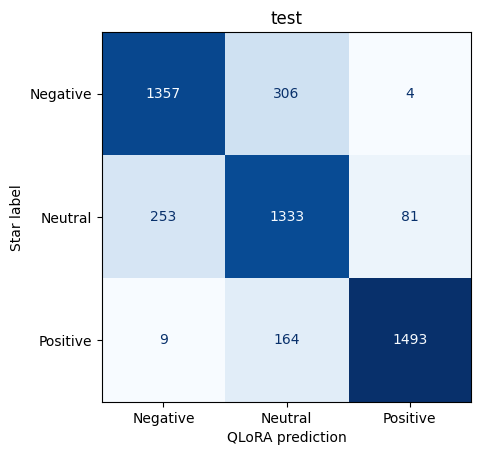

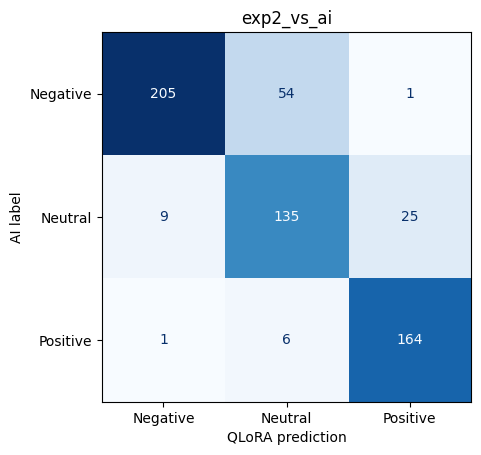

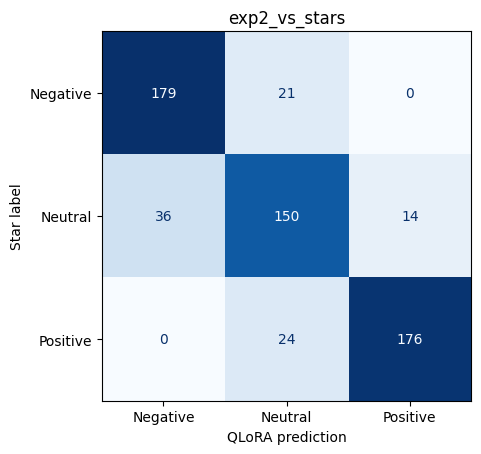

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

setting,QLoRA — val (600),QLoRA — test,QLoRA — Exp2 vs AI labels,QLoRA — Exp2 vs star labels (same 600)
n,600.000000,5000.000000,600.000000,600.000000
accuracy,0.836667,0.836600,0.840000,0.841667
macro_precision,0.843966,0.841210,0.836318,0.842702
macro_recall,0.836667,0.836612,0.848781,0.841667
macro_f1,0.839163,0.838232,0.837834,0.841569
micro_precision,0.836667,0.836600,0.840000,0.841667
micro_recall,0.836667,0.836600,0.840000,0.841667
micro_f1,0.836667,0.836600,0.840000,0.841667
invalid_rate,0.000000,0.000000,0.000000,0.000000
Negative_precision,0.813131,0.838172,0.953488,0.832558


In [13]:
test_pred = predict(test, 'test')
exp2_pred = predict(exp2, 'exp2')

rows = [
    val_row,
    metrics_row('QLoRA — test', test.label, test_pred),
    metrics_row('QLoRA — Exp2 vs AI labels', exp2.ai_label, exp2_pred),
    metrics_row('QLoRA — Exp2 vs star labels (same 600)', exp2.star_label, exp2_pred),
]
results = pd.DataFrame(rows)
results.to_csv(OUT / 'results_summary.csv', index=False)

save_cm('test', test.label, test_pred, 'Star label')
save_cm('exp2_vs_ai', exp2.ai_label, exp2_pred, 'AI label')
save_cm('exp2_vs_stars', exp2.star_label, exp2_pred, 'Star label')

# Timed the way Dinh timed his: 100 test reviews per class, after an untimed warm-up batch
timing_texts = pd.concat([g.sample(n=100, random_state=SEED) for _, g in test.groupby('label')]).text.tolist()
generate(timing_texts[:GEN_BS])
torch.cuda.synchronize(); t0 = time.perf_counter()
generate(timing_texts)
torch.cuda.synchronize(); sec = (time.perf_counter() - t0) / len(timing_texts)

cost = pd.DataFrame([{
    'setting': 'QLoRA', 'gpu_inference': GPU, 'batch_size': GEN_BS, 'timed_reviews': len(timing_texts),
    'sec_per_review': sec, 'reviews_per_sec': 1 / sec,
    'gpu_training': train_info['gpu'], 'training_minutes': train_info['train_minutes'],
    'train_n': train_info['train_n'], 'epochs': train_info['epochs']}])
cost.to_csv(OUT / 'inference_cost.csv', index=False)

results.set_index('setting').T

## 7. Summary to send to Dinh

In [14]:
for r in rows[1:]:
    print(f"\n{r['setting']} (n={r['n']})")
    print(f"  accuracy {r['accuracy']:.4f} | macro P/R/F1 {r['macro_precision']:.4f}/{r['macro_recall']:.4f}/{r['macro_f1']:.4f}"
          f" | micro P/R/F1 {r['micro_precision']:.4f}/{r['micro_recall']:.4f}/{r['micro_f1']:.4f}")
    for l in LABELS:
        print(f"  {l:<8} P {r[l + '_precision']:.4f}  R {r[l + '_recall']:.4f}  F1 {r[l + '_f1']:.4f}")
c = cost.iloc[0]
print(f"\nTraining: {c.training_minutes:.1f} min on {c.gpu_training} ({c.train_n} reviews, {c.epochs} epoch)")
print(f"Inference: {c.sec_per_review:.3f} s/review ({c.reviews_per_sec:.1f} reviews/s) on {c.gpu_inference}, batch {c.batch_size}")


QLoRA — test (n=5000)
  accuracy 0.8366 | macro P/R/F1 0.8412/0.8366/0.8382 | micro P/R/F1 0.8366/0.8366/0.8366
  Negative P 0.8382  R 0.8140  F1 0.8259
  Neutral  P 0.7393  R 0.7996  F1 0.7683
  Positive P 0.9461  R 0.8962  F1 0.9205

QLoRA — Exp2 vs AI labels (n=600)
  accuracy 0.8400 | macro P/R/F1 0.8363/0.8488/0.8378 | micro P/R/F1 0.8400/0.8400/0.8400
  Negative P 0.9535  R 0.7885  F1 0.8632
  Neutral  P 0.6923  R 0.7988  F1 0.7418
  Positive P 0.8632  R 0.9591  F1 0.9086

QLoRA — Exp2 vs star labels (same 600) (n=600)
  accuracy 0.8417 | macro P/R/F1 0.8427/0.8417/0.8416 | micro P/R/F1 0.8417/0.8417/0.8417
  Negative P 0.8326  R 0.8950  F1 0.8627
  Neutral  P 0.7692  R 0.7500  F1 0.7595
  Positive P 0.9263  R 0.8800  F1 0.9026

Training: 114.1 min on NVIDIA A100-SXM4-80GB (40000 reviews, 1 epoch)
Inference: 0.056 s/review (18.0 reviews/s) on NVIDIA A100-SXM4-80GB, batch 32
